In [1]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense


In [2]:
(x_train,_),(x_test,_)=mnist.load_data()

In [3]:
print("Training data shape:",x_train.shape)

Training data shape: (60000, 28, 28)


In [4]:
print("testing data shape:",x_test.shape)

testing data shape: (10000, 28, 28)


In [5]:
x_train=x_train.astype("float32")/255.0
x_test=x_test.astype("float32")/255.0
x_train=x_train.reshape(-1,784)
x_test=x_test.reshape(-1,784)
print("training data shape:",x_train.shape)
print("testing data shape:",x_test.shape)
print("minimum pixel value:",x_train.min())
print("Maximum pixel value:",x_train.max())
                        

training data shape: (60000, 784)
testing data shape: (10000, 784)
minimum pixel value: 0.0
Maximum pixel value: 1.0


In [6]:
inputs=Input(shape=(784,))
encoded=Dense(128,activation='relu')(inputs)
encoded=Dense(32,activation='relu')(encoded)
decoded=Dense(128,activation='relu')(encoded)
outputs=Dense(784,activation='sigmoid')(decoded)
autoencoder=Model(inputs,outputs)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           4,128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │           4,224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)
history=autoencoder.fit(x_train,x_train,epochs=3,batch_size=256,validation_split=0.1)

Epoch 1/3
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - loss: 0.0633 - val_loss: 0.0371
Epoch 2/3
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - loss: 0.0293 - val_loss: 0.0240
Epoch 3/3
211/211 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0217 - val_loss: 0.0197


In [ ]:
autoencoder.fit(
    x_train,
    x_train,
    epochs=3,
    batch_size=256,
    validation_split=0.1
)

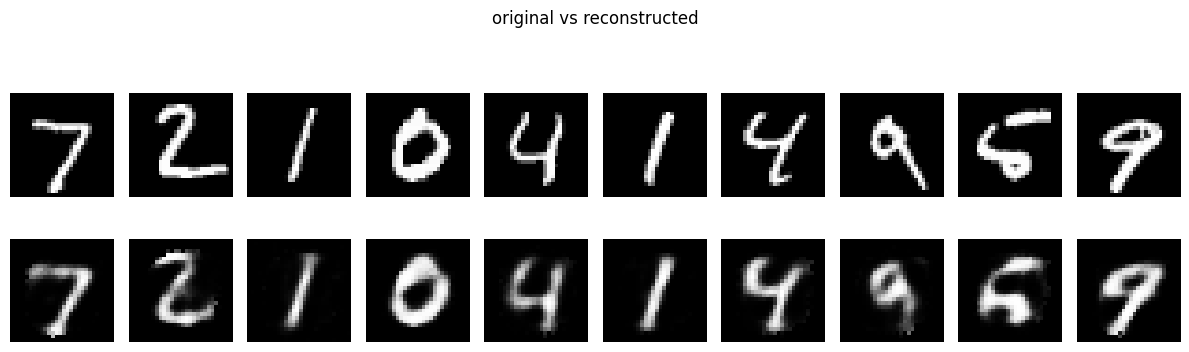

In [15]:
reconstructed=autoencoder.predict(x_test[:10],verbose=0)
plt.figure(figsize=(12,4))
for i in range(10):
    plt.subplot(2,10,i+1)
    plt.imshow(x_test[i].reshape(28,28),cmap="grey")
    plt.axis("off")
    plt.subplot(2,10,i+11)
    plt.imshow(reconstructed[i].reshape(28,28),cmap="grey")
    plt.axis("off")
plt.suptitle("original vs reconstructed")
plt.tight_layout()
plt.show()
    